# ĐỒ ÁN CUỐI KỲ: CSC17104 – LẬP TRÌNH CHO KHOA HỌC DỮ LIỆU
## PHẦN 2: PHÂN TÍCH CHUYÊN SÂU 5 CÂU HỎI NON-ML (Q1 - Q5) & TỔNG KẾT
---
Mỗi câu hỏi tuân thủ nghiêm ngặt 3 bước:
1. **Preprocessing:** Mô tả bằng Markdown, in và giải thích số dòng trước/sau.
2. **Analysis:** Giải thích phương pháp sử dụng và thực thi tính toán.
3. **Results:** Tối thiểu 2 biểu đồ chuẩn học thuật (đủ title, axes, units, legend, n), trả lời bằng số liệu cụ thể, thảo luận ý nghĩa thực tiễn, điểm bất ngờ và giới hạn.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('..'))
from src.visualization import set_academic_style
from src.utils import check_row_count, calculate_aggregated_rate, calculate_asr, cluster_bootstrap_ci

set_academic_style()
print("Module và thiết lập trực quan hóa đã sẵn sàng!")

Module và thiết lập trực quan hóa đã sẵn sàng!


### Q1 (TV1): Xu hướng tỷ lệ tử vong toàn cầu: Mẫu cố định (Fixed Cohort) vs Mẫu đầy đủ (All Available)
- **Tiêu chí:** D2, D3, D6

### Q2 (TV1): Chênh lệch tỷ lệ tử vong Nam - Nữ theo độ tuổi và Khoảng tin cậy Bootstrap 95% CI
- **Tiêu chí:** D3, D4, D5

### Q3 (TV2): Biến động GDP bình quân đầu người và Tỷ lệ tử vong trong cùng quốc gia
- **Tiêu chí:** D2, D3, D4, D6

### Q4 (TV2): Tác động của già hóa dân số: Tỷ lệ thô vs Tỷ lệ chuẩn hóa theo độ tuổi (ASR)
- **Tiêu chí:** D2, D3, D4, D6

---
## CÂU HỎI NGHIÊN CỨU 5 (Q5 - NON-ML)
### Khảo sát cơ chế thiếu dữ liệu HDI và sai lệch ước lượng theo độ tuổi & khu vực địa lý

**Câu hỏi:** Chỉ số phát triển con người (`HDI for year`) bị thiếu như thế nào theo quốc gia, khu vực và thời gian? Nếu chỉ giữ các dòng có HDI (*complete-case analysis*) thì ước lượng tỷ lệ tự tử theo nhóm tuổi và khu vực bị lệch bao nhiêu?

- **Người phụ trách:** Kiên
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D1 (Combining data):** Ghép bảng khu vực địa lý và nhóm thu nhập của World Bank (`data/raw/country_region.csv`) theo tên quốc gia; báo cáo số dòng trước/sau khi ghép, 11 tên nước không khớp và bảng ánh xạ.
  - **D2 (Reshaping & time):** Xây dựng ma trận trạng thái HDI theo quốc gia × năm giai đoạn 1985–2015; tách riêng nguồn *thiếu theo năm* và *thiếu theo quốc gia*.
  - **D3 (Derived variables):** Tạo cờ `is_missing_hdi`, biến phân loại nguồn thiếu `missing_type` và chỉ số sai lệch tương đối $\text{Bias}\%$.
  - **D4 (Controlling for a confounder):** Phân tầng $\text{Bias}\%$ theo 6 nhóm tuổi, giới tính, giai đoạn và khu vực địa lý.
  - **D5 (Quantifying uncertainty):** Kiểm định phi tham số hai mẫu (Mann-Whitney U, Kolmogorov-Smirnov) và khoảng tin cậy 95% cho $\text{Bias}\%$ bằng **cluster bootstrap theo quốc gia (1,000 lần lặp)**.
  - **D6 (Robustness check):** Tính lại $\text{Bias}\%$ khi bỏ Nga, bỏ 9 nước không bao giờ có HDI, chỉ giữ nước có độ phủ HDI $> 80\%$, và thay tỷ lệ gộp bằng trung vị.
- **Động cơ & Người dùng thụ hưởng (Target User):** Người phân tích dữ liệu y tế công cộng và các nhà dịch tễ học muốn đưa HDI vào mô hình (hồi quy, dự báo) trên bộ dữ liệu này. Cột HDI thiếu 69.94% (mục 3.2.4). Nhiều phân tích mặc định bỏ các dòng thiếu; nếu dữ liệu không thiếu hoàn toàn ngẫu nhiên (MCAR) thì cách đó làm sai lệch kết luận.
- **Quyết định hỗ trợ (Actionable Decision):** Có nên dùng HDI làm biến giải thích hay không; nếu dùng thì có được bỏ các dòng thiếu HDI không, hay phải phân tích riêng hoặc tìm nguồn HDI khác.

### 1. Tiền xử lý dữ liệu (Preprocessing for Q5)
- **Bước 1:** Đọc `master.csv`, đổi tên cột cho gọn, **loại năm 2016** (chỉ 16 nước và thiếu nhóm 5-14, xem mục 3.2.4).
- **Bước 2 (D1):** Ghép `data/raw/country_region.csv` để có khu vực và nhóm thu nhập của từng nước.
- **Bước 3 (D3):** Tạo cờ thiếu HDI và phân loại nguồn thiếu.
- **Bước 4:** Lọc riêng 10 năm có HDI để dùng cho các phân tích chỉ xét nguồn "thiếu theo quốc gia".
- Sau mỗi bước lọc hoặc ghép, số dòng trước/sau được in bằng hàm `check_row_count`.

> **Lưu ý phương pháp luận:** Tỷ lệ luôn tính theo công thức gộp $100{,}000 \times \sum \text{ca} / \sum \text{dân số}$, không lấy trung bình cột `suicides/100k pop`, vì các phân nhóm có quy mô dân số rất khác nhau.

In [2]:
%matplotlib inline
from IPython.display import display
from scipy import stats
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.visualization import save_figure

# Bước 1: đọc dữ liệu, đổi tên cột, loại năm 2016
q5_raw = pd.read_csv(os.path.join('..', 'data', 'raw', 'master.csv'))
q5 = q5_raw.rename(columns={
    'suicides/100k pop': 'rate',
    'HDI for year': 'hdi',
    ' gdp_for_year ($) ': 'gdp_for_year',
    'gdp_per_capita ($)': 'gdp_per_capita',
})
q5_before = q5
q5 = q5[q5['year'] != 2016].copy()
check_row_count(q5_before, q5, "Q5 - Loại năm 2016")
print("Nước chỉ có số liệu năm 2016 (bị loại theo):",
      sorted(set(q5_before['country']) - set(q5['country'])))

[Q5 - Loại năm 2016]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)

Nước chỉ có số liệu năm 2016 (bị loại theo): ['Mongolia']


**Bước 2 (D1): ghép khu vực và nhóm thu nhập.**

- **Nguồn:** World Bank, *Country and Lending Groups*, lấy qua API `https://api.worldbank.org/v2/country?format=json&per_page=400` ngày 23/11/2026, giấy phép CC BY 4.0. File `data/raw/country_region.csv` giữ 217 nền kinh tế (đã bỏ các dòng tổng hợp như "World", "High income") với 4 cột: `iso3`, `country_wb`, `region`, `income_group`.
- **Khóa ghép:** tên nước. Hai nguồn đặt tên khác nhau, nên nhóm ghép thử bằng tên gốc để liệt kê các tên không khớp, chuẩn hóa bằng một bảng ánh xạ tường minh, rồi mới ghép thật với `validate='many_to_one'` (mỗi nước chỉ có một dòng trong bảng vùng).
- **Lưu ý:** `income_group` là phân loại **hiện tại** của World Bank, không phải phân loại theo từng năm 1985–2015.
- **Kiểm tra số dòng:** đây là phép ghép trái nhiều–một, mỗi dòng chỉ được gắn thêm các cột của World Bank, nên số dòng phải giữ nguyên. Sau khi chuẩn hóa tên, không còn dòng nào thiếu khu vực.

In [3]:
q5_regions = pd.read_csv(os.path.join('..', 'data', 'raw', 'country_region.csv'))
assert q5_regions['country_wb'].is_unique
print(f"country_region.csv: {len(q5_regions)} nền kinh tế")

# Ghép thử bằng tên gốc để tìm khóa không khớp
q5_names = pd.Series(sorted(q5['country'].unique()))
q5_unmatched = q5_names[~q5_names.isin(q5_regions['country_wb'])]
print(f"Số nước trong dữ liệu: {len(q5_names)}, "
      f"không khớp tên: {len(q5_unmatched)}")

# Bảng ánh xạ tên của dữ liệu gốc -> tên của World Bank
Q5_NAME_MAP = {
    'Bahamas': 'Bahamas, The',
    'Czech Republic': 'Czechia',
    'Kyrgyzstan': 'Kyrgyz Republic',
    'Macau': 'Macao SAR, China',
    'Puerto Rico': 'Puerto Rico (US)',
    'Republic of Korea': 'Korea, Rep.',
    'Saint Kitts and Nevis': 'St. Kitts and Nevis',
    'Saint Lucia': 'St. Lucia',
    'Saint Vincent and Grenadines': 'St. Vincent and the Grenadines',
    'Slovakia': 'Slovak Republic',
    'Turkey': 'Turkiye',
}
assert set(Q5_NAME_MAP) == set(q5_unmatched)
assert set(Q5_NAME_MAP.values()) <= set(q5_regions['country_wb'])
display(pd.DataFrame({'Tên trong master.csv': list(Q5_NAME_MAP),
                      'Tên World Bank': list(Q5_NAME_MAP.values())}))

q5['country_wb'] = q5['country'].replace(Q5_NAME_MAP)
q5_before = q5
q5 = q5.merge(q5_regions, on='country_wb', how='left',
              validate='many_to_one')
check_row_count(q5_before, q5, "Q5 - Ghép khu vực World Bank (D1)")
print("Số dòng chưa có khu vực sau khi chuẩn hóa tên:",
      q5['region'].isna().sum())

# Tên khu vực tiếng Việt cho biểu đồ
Q5_REGION_VI = {
    'Europe & Central Asia': 'Châu Âu & Trung Á',
    'Latin America & Caribbean': 'Mỹ Latinh & Caribe',
    'East Asia & Pacific': 'Đông Á & Thái Bình Dương',
    'Middle East, North Africa, Afghanistan & Pakistan':
        'Trung Đông & Bắc Phi (gồm AF, PK)',
    'Sub-Saharan Africa': 'Châu Phi hạ Sahara',
    'North America': 'Bắc Mỹ',
    'South Asia': 'Nam Á',
}
q5['region_vi'] = q5['region'].map(Q5_REGION_VI)
q5_countries = q5.drop_duplicates('country')
display(q5_countries.groupby('region_vi').size()
        .sort_values(ascending=False).rename('Số quốc gia').to_frame())

country_region.csv: 217 nền kinh tế
Số nước trong dữ liệu: 100, không khớp tên: 11


,Tên trong master.csv,Tên World Bank
0,Bahamas,"Bahamas, The"
1,Czech Republic,Czechia
2,Kyrgyzstan,Kyrgyz Republic
3,Macau,"Macao SAR, China"
4,Puerto Rico,Puerto Rico (US)
5,Republic of Korea,"Korea, Rep."
6,Saint Kitts and Nevis,St. Kitts and Nevis
7,Saint Lucia,St. Lucia
8,Saint Vincent and Grenadines,St. Vincent and the Grenadines
9,Slovakia,Slovak Republic


[Q5 - Ghép khu vực World Bank (D1)]
  • Số dòng trước : 27,660
  • Số dòng sau   : 27,660
  • Thay đổi      : +0 dòng (+0.00%)

Số dòng chưa có khu vực sau khi chuẩn hóa tên: 0


,Số quốc gia
region_vi,
Châu Âu & Trung Á,46
Mỹ Latinh & Caribe,29
Đông Á & Thái Bình Dương,10
"Trung Đông & Bắc Phi (gồm AF, PK)",7
Châu Phi hạ Sahara,4
Bắc Mỹ,2
Nam Á,2


In [4]:
# Bước 3 (D3): cờ thiếu HDI và phân loại nguồn thiếu
q5_hdi_years = sorted(q5.loc[q5['hdi'].notna(), 'year'].unique())
q5['is_missing_hdi'] = q5['hdi'].isna()
q5['in_hdi_year'] = q5['year'].isin(q5_hdi_years)
q5['missing_type'] = np.select(
    [~q5['is_missing_hdi'], ~q5['in_hdi_year']],
    ['Có HDI', 'Thiếu theo năm'],
    default='Thiếu theo nước',
)
print("Các năm có HDI:", q5_hdi_years)

q5_cy = q5.drop_duplicates(['country', 'year'])
q5_type_table = pd.DataFrame({
    'Số dòng': q5['missing_type'].value_counts(),
    'Số cặp country-year': q5_cy['missing_type'].value_counts(),
})
q5_type_table['% số dòng'] = (100 * q5_type_table['Số dòng']
                              / len(q5)).round(2)
display(q5_type_table)

Các năm có HDI: [1985, 1990, 1995, 2000, 2005, 2010, 2011, 2012, 2013, 2014]


,Số dòng,Số cặp country-year,% số dòng
missing_type,,,
Thiếu theo năm,18384,1532,66.46
Có HDI,8364,697,30.24
Thiếu theo nước,912,76,3.30


**Bước 4: lọc 10 năm có HDI.** HDI chỉ có ở các năm 1985, 1990, 1995, 2000, 2005 và 2010–2014; ở 21 năm còn lại mọi quốc gia đều thiếu HDI (*thiếu theo năm*). Các phân tích b)–e) ở mục 2 chỉ xét 10 năm này để tách riêng nguồn *thiếu theo quốc gia*. Số dòng giảm vì các dòng thuộc 21 năm không có HDI bị bỏ ra.

In [5]:
# Bước 4: chỉ giữ 10 năm có HDI
q5_h = q5[q5['in_hdi_year']]
check_row_count(q5, q5_h, "Q5 - Giữ 10 năm có HDI")
q5_hcy = q5_h.drop_duplicates(['country', 'year'])

[Q5 - Giữ 10 năm có HDI]
  • Số dòng trước : 27,660
  • Số dòng sau   : 9,276
  • Thay đổi      : -18,384 dòng (-66.46%)



### 2. Phân tích thống kê (Analysis for Q5)
Phần phân tích gồm 5 bước a)–e). Bảng số liệu của từng bước được in ngay bên dưới; biểu đồ tương ứng nằm ở mục 3.

**a) Thiếu theo thời gian và theo quốc gia (D2).** Dữ liệu được chuyển thành ma trận quốc gia × năm (*pivot*), mỗi ô mang một trong ba trạng thái: không có số liệu năm đó, có số liệu tự tử nhưng thiếu HDI, có HDI (Hình Q5.1). Bảng dưới đây cho tỷ lệ cặp country-year có HDI theo từng năm.

In [6]:
q5_status = (q5_cy.assign(code=np.where(q5_cy['is_missing_hdi'], 1, 2))
             .pivot(index='country', columns='year', values='code')
             .reindex(columns=range(1985, 2016))
             .fillna(0))
q5_order = q5_countries.sort_values(['region_vi', 'country'])
q5_status = q5_status.loc[q5_order['country']]

# Tỷ lệ country-year có HDI theo năm: các năm ngoài 10 năm có HDI đều là 0%
q5_by_year = q5_cy.groupby('year')['is_missing_hdi'].agg(['size', 'mean'])
q5_by_year['% có HDI'] = (100 * (1 - q5_by_year['mean'])).round(1)
assert (q5_by_year.drop(index=q5_hdi_years)['% có HDI'] == 0).all()
print("Tỷ lệ country-year có HDI trong 10 năm có HDI "
      "(21 năm còn lại đều 0%):")
display(q5_by_year.loc[q5_hdi_years]
        .rename(columns={'size': 'Số country-year'})
        [['Số country-year', '% có HDI']].T)

Tỷ lệ country-year có HDI trong 10 năm có HDI (21 năm còn lại đều 0%):


year,1985,1990,1995,2000,2005,2010,2011,2012,2013,2014
Số country-year,48.0,64.0,78.0,86.0,84.0,88.0,86.0,81.0,80.0,78.0
% có HDI,77.1,78.1,80.8,88.4,90.5,95.5,94.2,96.3,96.2,96.2


**b) Thiếu theo khu vực và nhóm thu nhập (D1, D4).** Để tách khỏi "thiếu theo năm" (năm đó cả thế giới không có HDI), phần này chỉ xét **10 năm có HDI** (bảng `q5_h` ở Bước 4). Đơn vị đếm là cặp country-year.

In [7]:
def q5_missing_by(col):
    # Tỷ lệ country-year thiếu HDI trong 10 năm có HDI
    t = q5_hcy.groupby(col).agg(
        so_quoc_gia=('country', 'nunique'),
        so_country_year=('country', 'size'),
        pct_thieu=('is_missing_hdi', 'mean'))
    t['pct_thieu'] = (100 * t['pct_thieu']).round(1)
    return t.sort_values('pct_thieu', ascending=False)


q5_miss_region = q5_missing_by('region_vi')
q5_miss_income = q5_missing_by('income_group')
display(q5_miss_region, q5_miss_income)

q5_never = q5_hcy.groupby('country')['is_missing_hdi'].all()
q5_never = q5_countries.set_index('country').loc[
    q5_never[q5_never].index, ['region_vi', 'income_group']]
q5_absent = sorted(set(q5['country']) - set(q5_h['country']))
print(f"Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: "
      f"{len(q5_never)}")
display(q5_never)
print("Nước không có dòng nào trong 10 năm có HDI:", q5_absent)

,so_quoc_gia,so_country_year,pct_thieu
region_vi,,,
Đông Á & Thái Bình Dương,9,66,21.2
Mỹ Latinh & Caribe,29,237,15.6
Châu Phi hạ Sahara,4,25,8.0
Châu Âu & Trung Á,46,372,6.2
Bắc Mỹ,2,19,0.0
Nam Á,2,6,0.0
"Trung Đông & Bắc Phi (gồm AF, PK)",7,48,0.0


,so_quoc_gia,so_country_year,pct_thieu
income_group,,,
Lower middle income,4,25,16.0
Upper middle income,36,253,9.9
High income,59,495,9.5


Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: 9


,region_vi,income_group
country,,
Aruba,Mỹ Latinh & Caribe,High income
Cabo Verde,Châu Phi hạ Sahara,Upper middle income
Dominica,Mỹ Latinh & Caribe,Upper middle income
Kiribati,Đông Á & Thái Bình Dương,Lower middle income
Puerto Rico,Mỹ Latinh & Caribe,High income
Republic of Korea,Đông Á & Thái Bình Dương,High income
Russian Federation,Châu Âu & Trung Á,High income
Saint Kitts and Nevis,Mỹ Latinh & Caribe,High income
San Marino,Châu Âu & Trung Á,High income


Nước không có dòng nào trong 10 năm có HDI: ['Macau']


**c) Độ lệch của complete-case (D3, D4).** Với mỗi phân nhóm, tỷ lệ gộp trên **mọi dòng** được so với tỷ lệ gộp trên **các dòng có HDI**:

$$\text{Bias}\% = \frac{\text{Rate}_{\text{Complete}} - \text{Rate}_{\text{All}}}{\text{Rate}_{\text{All}}} \times 100$$

Có hai phạm vi so sánh:

- **Toàn kỳ 1985–2015:** đúng với việc "xóa mọi dòng thiếu HDI". Độ lệch ở đây gộp cả hai nguồn thiếu, gồm cả tác động của việc chỉ còn 10 năm.
- **Trong 10 năm có HDI:** chỉ còn nguồn "thiếu theo nước". Đây là phạm vi chính để đánh giá thiên lệch chọn mẫu.

In [8]:
Q5_AGES = ['5-14 years', '15-24 years', '25-34 years', '35-54 years',
           '55-74 years', '75+ years']


def q5_bias_table(data, by):
    # Tỷ lệ gộp trên mọi dòng và trên các dòng có HDI, kèm Bias%
    cols = ['suicides_no', 'population']
    s_all = data.groupby(by)[cols].sum()
    s_cc = data[~data['is_missing_hdi']].groupby(by)[cols].sum()
    t = pd.DataFrame({
        'rate_all': 1e5 * s_all['suicides_no'] / s_all['population'],
        'rate_complete': 1e5 * s_cc['suicides_no'] / s_cc['population'],
    })
    t['bias_pct'] = 100 * (t['rate_complete'] - t['rate_all']) / t['rate_all']
    return t.round(2)


q5_overall = pd.DataFrame({
    'rate_all': [calculate_aggregated_rate(q5),
                 calculate_aggregated_rate(q5_h)],
    'rate_complete': [calculate_aggregated_rate(q5[~q5['is_missing_hdi']])] * 2,
}, index=['Toàn kỳ 1985–2015', 'Trong 10 năm có HDI'])
q5_overall['bias_pct'] = (100 * (q5_overall['rate_complete']
                                 - q5_overall['rate_all'])
                          / q5_overall['rate_all'])
print("Tổng thể:")
display(q5_overall.round(2))
print("Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI:",
      round(calculate_aggregated_rate(q5_h[q5_h['is_missing_hdi']]), 2))

q5_bias_age = pd.concat(
    {'Toàn kỳ': q5_bias_table(q5, 'age'),
     '10 năm có HDI': q5_bias_table(q5_h, 'age')}, axis=1).loc[Q5_AGES]
print("\nTheo nhóm tuổi:")
display(q5_bias_age)

q5_h = q5_h.assign(period=np.where(q5_h['year'] >= 2010,
                                   '2010–2014 (hằng năm)',
                                   '1985–2005 (5 năm/lần)'))
print("Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:")
display(q5_bias_table(q5_h, 'region_vi').sort_values('bias_pct'))
display(q5_bias_table(q5_h, 'sex'))
display(q5_bias_table(q5_h, 'period'))

Tổng thể:


,rate_all,rate_complete,bias_pct
Toàn kỳ 1985–2015,13.15,11.13,-15.39
Trong 10 năm có HDI,12.68,11.13,-12.24


Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI: 25.93

Theo nhóm tuổi:


Toàn kỳ                        10 năm có HDI                \
            rate_all rate_complete bias_pct      rate_all rate_complete   
age                                                                       
5-14 years      0.62          0.58    -6.93          0.64          0.58   
15-24 years     9.36          8.09   -13.64          9.18          8.09   
25-34 years    13.33         10.82   -18.83         12.82         10.82   
35-54 years    17.07         14.05   -17.72         16.14         14.05   
55-74 years    18.85         15.97   -15.28         17.69         15.97   
75+ years      24.54         20.97   -14.58         22.95         20.97   

                      
            bias_pct  
age                   
5-14 years     -9.21  
15-24 years   -11.87  
25-34 years   -15.58  
35-54 years   -12.93  
55-74 years    -9.70  
75+ years      -8.66

Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:


,rate_all,rate_complete,bias_pct
region_vi,,,
Châu Âu & Trung Á,15.74,13.06,-17.02
Đông Á & Thái Bình Dương,16.33,14.97,-8.31
Châu Phi hạ Sahara,1.32,1.31,-0.99
Mỹ Latinh & Caribe,5.63,5.61,-0.42
Bắc Mỹ,13.15,13.15,0.00
Nam Á,33.92,33.92,0.00
"Trung Đông & Bắc Phi (gồm AF, PK)",3.97,3.97,0.00


,rate_all,rate_complete,bias_pct
sex,,,
female,5.75,5.20,-9.52
male,19.94,17.29,-13.29


,rate_all,rate_complete,bias_pct
period,,,
1985–2005 (5 năm/lần),13.72,11.86,-13.56
2010–2014 (hằng năm),11.86,10.57,-10.94


**d) Kiểm định và khoảng tin cậy (D5).**

- **So sánh phân phối:** trong 10 năm có HDI, tỷ lệ được gộp về cấp country-year, rồi nhóm thiếu HDI được so với nhóm có HDI bằng **Mann-Whitney U** (so vị trí, không giả định phân phối chuẩn) và **Kolmogorov-Smirnov** (so toàn bộ hình dạng phân phối). Hai kiểm định này coi các country-year là độc lập, trong khi các năm của cùng một nước thì tương quan với nhau, nên p-value chỉ mang tính tham khảo.
- **Khoảng tin cậy cho Bias%:** dùng `cluster_bootstrap_ci` trong `src/utils.py`, lấy mẫu lại **theo quốc gia** 1,000 lần. Cách này giữ nguyên sự phụ thuộc giữa các năm trong cùng một nước.

In [9]:
# Kiểm định trên tỷ lệ gộp cấp country-year
q5_cyr = (q5_h.groupby(['country', 'year'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cyr['rate'] = 1e5 * q5_cyr['suicides_no'] / q5_cyr['population']
q5_miss_r = q5_cyr.loc[q5_cyr['is_missing_hdi'], 'rate']
q5_have_r = q5_cyr.loc[~q5_cyr['is_missing_hdi'], 'rate']
q5_mwu = stats.mannwhitneyu(q5_miss_r, q5_have_r, alternative='two-sided')
q5_ks = stats.ks_2samp(q5_miss_r, q5_have_r)
print(f"Country-year thiếu HDI: n = {len(q5_miss_r)}, "
      f"trung vị = {q5_miss_r.median():.2f}/100k")
print(f"Country-year có HDI:   n = {len(q5_have_r)}, "
      f"trung vị = {q5_have_r.median():.2f}/100k")
print(f"Mann-Whitney U: U = {q5_mwu.statistic:,.1f}, "
      f"p = {q5_mwu.pvalue:.4f}")
print(f"Kolmogorov-Smirnov: D = {q5_ks.statistic:.4f}, "
      f"p = {q5_ks.pvalue:.4f}")

# Kiểm định theo từng nhóm tuổi (tỷ lệ gộp hai giới, cấp country-year-age)
q5_cya = (q5_h.groupby(['country', 'year', 'age'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cya['rate'] = 1e5 * q5_cya['suicides_no'] / q5_cya['population']
q5_age_tests = []
for age in Q5_AGES:
    g = q5_cya[q5_cya['age'] == age]
    a = g.loc[g['is_missing_hdi'], 'rate']
    b = g.loc[~g['is_missing_hdi'], 'rate']
    q5_age_tests.append({
        'age': age, 'n_thieu': len(a), 'n_co': len(b),
        'trung_vi_thieu': round(a.median(), 2),
        'trung_vi_co': round(b.median(), 2),
        'p_mann_whitney': stats.mannwhitneyu(
            a, b, alternative='two-sided').pvalue,
    })
q5_age_tests = pd.DataFrame(q5_age_tests).set_index('age')
display(q5_age_tests.round(4))


def q5_bias_pct(data):
    # Bias% tổng thể của một tập dữ liệu (dùng cho bootstrap)
    r_all = calculate_aggregated_rate(data)
    r_cc = calculate_aggregated_rate(data[~data['is_missing_hdi']])
    return 100 * (r_cc - r_all) / r_all


q5_ci = cluster_bootstrap_ci(
    q5_h[['country', 'suicides_no', 'population', 'is_missing_hdi']],
    cluster_col='country', calc_func=q5_bias_pct,
    n_bootstraps=1000, random_state=42)
print(f"Bias% trong 10 năm có HDI: {q5_bias_pct(q5_h):.2f}% "
      f"(KTC 95% cluster bootstrap: {q5_ci[0]:.2f}% đến {q5_ci[1]:.2f}%)")

Country-year thiếu HDI: n = 76, trung vị = 8.53/100k
Country-year có HDI:   n = 697, trung vị = 10.35/100k
Mann-Whitney U: U = 25,028.5, p = 0.4306
Kolmogorov-Smirnov: D = 0.1189, p = 0.2639


,n_thieu,n_co,trung_vi_thieu,trung_vi_co,p_mann_whitney
age,,,,,
5-14 years,76,697,0.40,0.40,0.1240
15-24 years,76,697,7.01,7.33,0.1688
25-34 years,76,697,10.47,9.40,0.5716
35-54 years,76,697,12.65,12.52,0.9646
55-74 years,76,697,11.85,12.60,0.9890
75+ years,76,697,11.40,13.65,0.4833


Bias% trong 10 năm có HDI: -12.24% (KTC 95% cluster bootstrap: -29.07% đến 0.18%)


**e) Kiểm tra độ vững (D6).** Tỷ lệ gộp bị chi phối bởi các nước đông dân, nên Bias% (trong 10 năm có HDI) được tính lại khi thay đổi cách tính:

1. **Bỏ Nga:** Nga đông dân, tỷ lệ cao và không bao giờ có HDI.
2. **Bỏ 9 nước không bao giờ có HDI:** chỉ còn các nước thiếu HDI ở một vài năm.
3. **Chỉ nước có độ phủ HDI > 80%** (độ phủ = tỷ lệ country-year có HDI trong 10 năm có HDI), và so với nhóm nước có độ phủ < 30%.
4. **Dùng trung vị** tỷ lệ cấp country-year thay cho tỷ lệ gộp.

In [10]:
q5_cov = 1 - q5_hcy.groupby('country')['is_missing_hdi'].mean()
q5_high = q5_cov[q5_cov > 0.8].index
q5_low = q5_cov[q5_cov < 0.3].index
print(f"Độ phủ HDI > 80%: {len(q5_high)} nước; < 30%: {len(q5_low)} nước; "
      f"30–80%: {len(q5_cov) - len(q5_high) - len(q5_low)} nước")
print(f"Tỷ lệ gộp nhóm độ phủ cao: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_high)]):.2f}"
      f"; nhóm độ phủ thấp: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_low)]):.2f}"
      " (ca/100k)")

q5_variants = {
    'Chính: mọi nước, tỷ lệ gộp': q5_h,
    'Bỏ Nga': q5_h[q5_h['country'] != 'Russian Federation'],
    'Bỏ 9 nước không bao giờ có HDI':
        q5_h[~q5_h['country'].isin(q5_never.index)],
    'Chỉ nước có độ phủ HDI > 80%': q5_h[q5_h['country'].isin(q5_high)],
}
q5_robust = pd.DataFrame({
    name: {'so_nuoc': d['country'].nunique(),
           'rate_all': calculate_aggregated_rate(d),
           'rate_complete': calculate_aggregated_rate(
               d[~d['is_missing_hdi']]),
           'bias_pct': q5_bias_pct(d)}
    for name, d in q5_variants.items()}).T
q5_med_all = q5_cyr['rate'].median()
q5_med_cc = q5_have_r.median()
q5_robust.loc['Trung vị country-year thay cho tỷ lệ gộp'] = [
    q5_h['country'].nunique(), q5_med_all, q5_med_cc,
    100 * (q5_med_cc - q5_med_all) / q5_med_all]
q5_robust['so_nuoc'] = q5_robust['so_nuoc'].astype(int)
display(q5_robust.round(2))

Độ phủ HDI > 80%: 78 nước; < 30%: 9 nước; 30–80%: 12 nước
Tỷ lệ gộp nhóm độ phủ cao: 11.17; nhóm độ phủ thấp: 26.83 (ca/100k)


,so_nuoc,rate_all,rate_complete,bias_pct
"Chính: mọi nước, tỷ lệ gộp",99,12.68,11.13,-12.24
Bỏ Nga,98,11.46,11.13,-2.91
Bỏ 9 nước không bao giờ có HDI,90,11.13,11.13,-0.03
Chỉ nước có độ phủ HDI > 80%,78,11.17,11.17,-0.02
Trung vị country-year thay cho tỷ lệ gộp,99,10.06,10.35,2.88


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q5)
Bốn biểu đồ dưới đây trình bày kết quả của mục 2:
- **Hình Q5.1 (D2):** ma trận trạng thái HDI theo quốc gia × năm. Ô xám là năm nước đó không có trong dữ liệu, ô cam là có số liệu tự tử nhưng thiếu HDI, ô xanh là có HDI.
- **Hình Q5.2 (D1, D4):** tỷ lệ thiếu HDI theo khu vực và nhóm thu nhập trong 10 năm có HDI.
- **Hình Q5.3 (D3, D4, D5):** tỷ lệ tự tử theo nhóm tuổi trên mọi dòng so với complete-case, kèm Bias% và p-value Mann-Whitney U.
- **Hình Q5.4 (D6):** Bias% dưới các cách tính khác nhau.

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig1_hdi_matrix.png


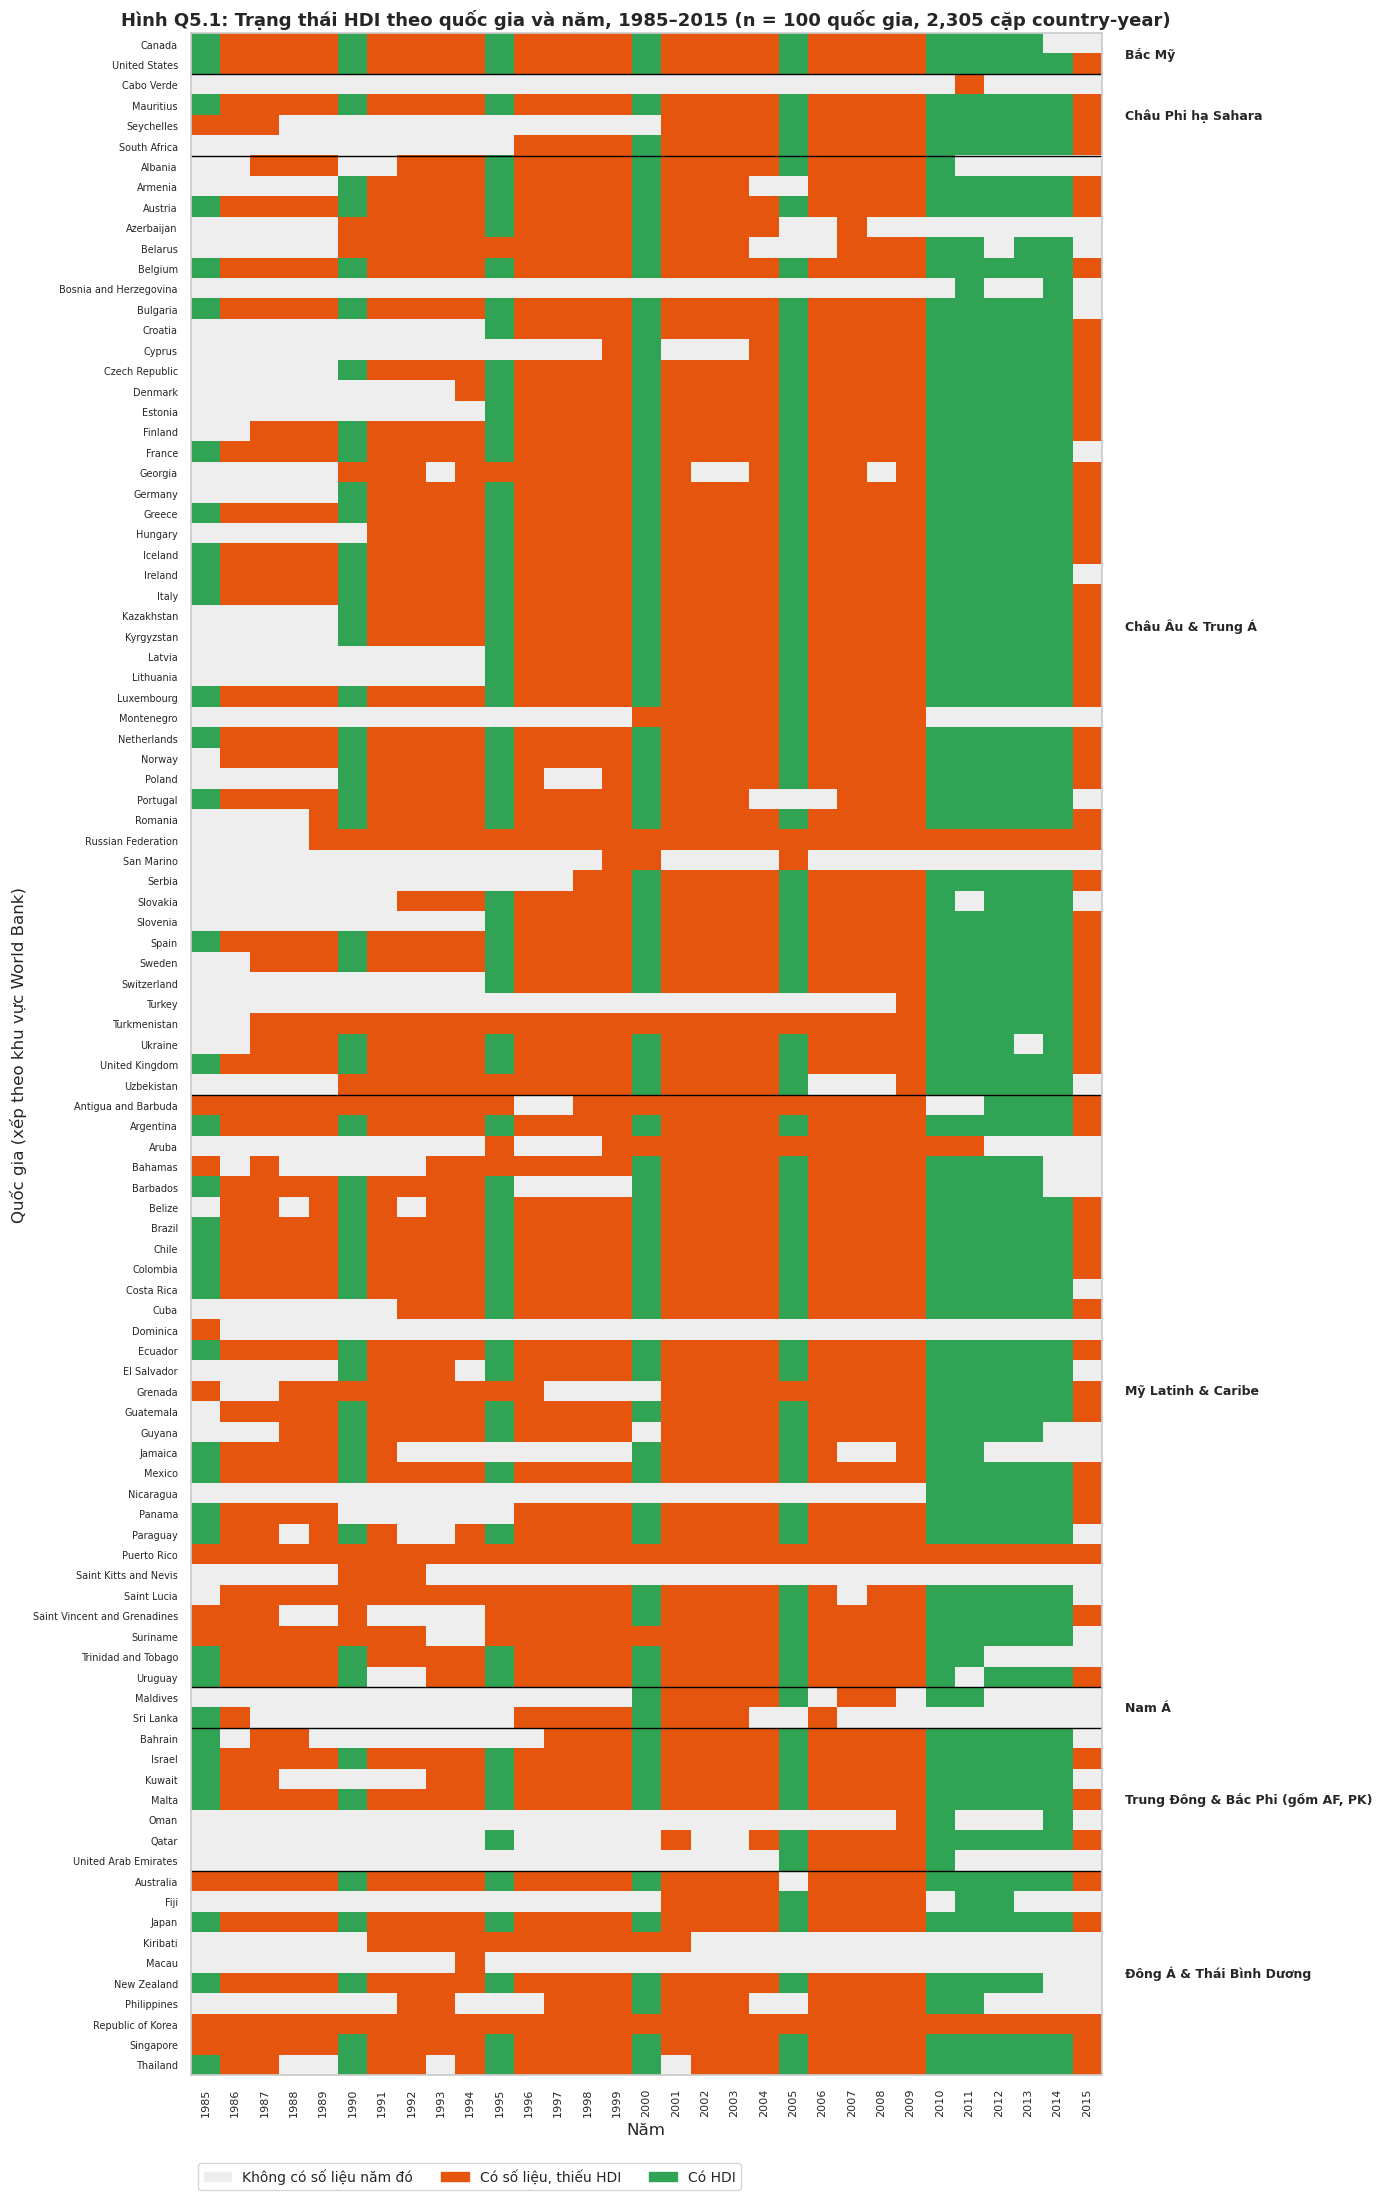

In [11]:
fig, ax = plt.subplots(figsize=(14, 22))
cmap = ListedColormap(['#eeeeee', '#e6550d', '#31a354'])
ax.imshow(q5_status.to_numpy(), aspect='auto', cmap=cmap,
          vmin=0, vmax=2, interpolation='none')
ax.set_xticks(range(q5_status.shape[1]))
ax.set_xticklabels(q5_status.columns, rotation=90, fontsize=8)
ax.set_yticks(range(q5_status.shape[0]))
ax.set_yticklabels(q5_status.index, fontsize=7)
ax.grid(False)

# Đường phân cách và nhãn khu vực
q5_bounds = q5_order['region_vi'].to_numpy()
for i in range(1, len(q5_bounds)):
    if q5_bounds[i] != q5_bounds[i - 1]:
        ax.axhline(i - 0.5, color='black', linewidth=1)
for reg_name, pos in (q5_order.reset_index(drop=True)
                      .groupby('region_vi').groups.items()):
    ax.text(q5_status.shape[1] + 0.3, np.mean(pos), reg_name,
            va='center', fontsize=9, fontweight='bold')

ax.legend(handles=[Patch(color='#eeeeee', label='Không có số liệu năm đó'),
                   Patch(color='#e6550d', label='Có số liệu, thiếu HDI'),
                   Patch(color='#31a354', label='Có HDI')],
          loc='upper left', bbox_to_anchor=(0, -0.04), ncol=3)
ax.set_xlabel('Năm')
ax.set_ylabel('Quốc gia (xếp theo khu vực World Bank)')
ax.set_title('Hình Q5.1: Trạng thái HDI theo quốc gia và năm, 1985–2015 '
             f'(n = {q5_status.shape[0]} quốc gia, '
             f'{len(q5_cy):,} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig1_hdi_matrix.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig2_missing_by_region.png


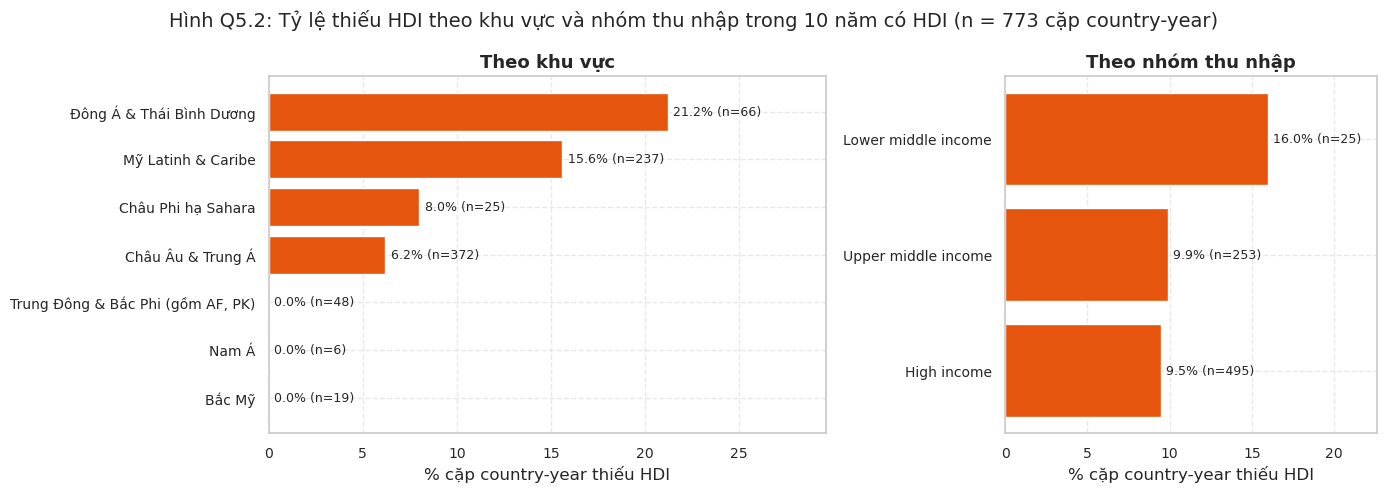

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         gridspec_kw={'width_ratios': [3, 2]})
for ax, t, title in [(axes[0], q5_miss_region, 'Theo khu vực'),
                     (axes[1], q5_miss_income, 'Theo nhóm thu nhập')]:
    t = t.sort_values('pct_thieu')
    ax.barh(t.index, t['pct_thieu'], color='#e6550d')
    for i, (p, n) in enumerate(zip(t['pct_thieu'], t['so_country_year'])):
        ax.text(p + 0.3, i, f"{p:.1f}% (n={n})", va='center', fontsize=9)
    ax.set_xlabel('% cặp country-year thiếu HDI')
    ax.set_title(title)
    ax.set_xlim(0, t['pct_thieu'].max() * 1.35 + 1)
fig.suptitle('Hình Q5.2: Tỷ lệ thiếu HDI theo khu vực và nhóm thu nhập '
             f'trong 10 năm có HDI (n = {len(q5_hcy)} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig2_missing_by_region.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig3_bias_by_age.png


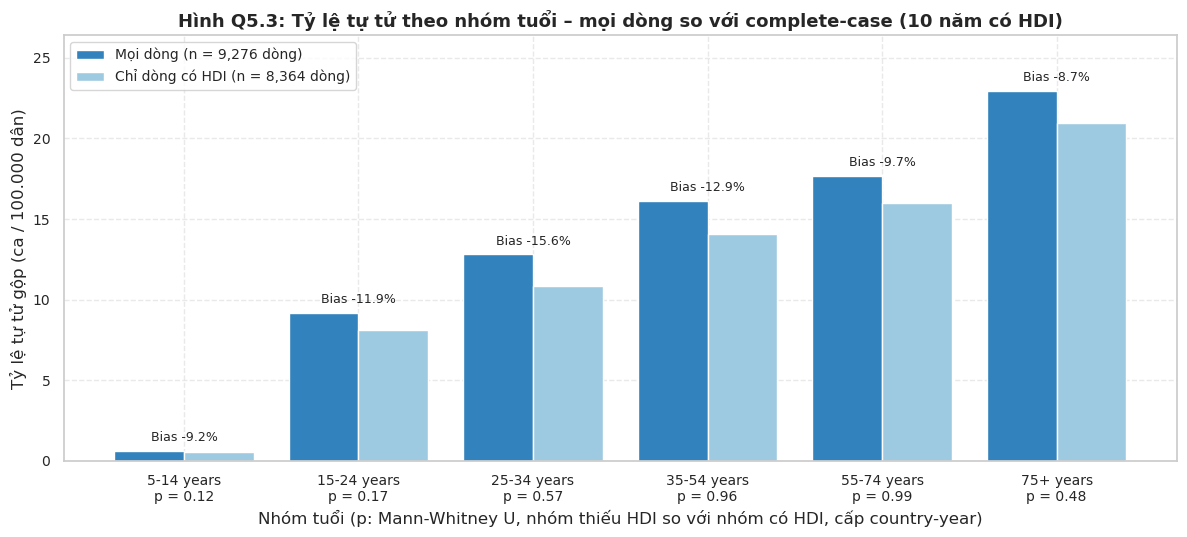

In [13]:
q5_plot = q5_bias_age['10 năm có HDI']
x = np.arange(len(Q5_AGES))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x - 0.2, q5_plot['rate_all'], width=0.4, color='#3182bd',
       label=f'Mọi dòng (n = {len(q5_h):,} dòng)')
ax.bar(x + 0.2, q5_plot['rate_complete'], width=0.4, color='#9ecae1',
       label=f'Chỉ dòng có HDI (n = {(~q5_h["is_missing_hdi"]).sum():,} dòng)')
for i, (top, b) in enumerate(zip(q5_plot[['rate_all', 'rate_complete']]
                                 .max(axis=1), q5_plot['bias_pct'])):
    ax.text(i, top + 0.6, f"Bias {b:+.1f}%", ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\np = {p:.2f}" for a, p in
                    zip(Q5_AGES, q5_age_tests['p_mann_whitney'])])
ax.set_xlabel('Nhóm tuổi (p: Mann-Whitney U, nhóm thiếu HDI so với nhóm '
              'có HDI, cấp country-year)')
ax.set_ylabel('Tỷ lệ tự tử gộp (ca / 100.000 dân)')
ax.set_ylim(0, q5_plot['rate_all'].max() * 1.15)
ax.set_title('Hình Q5.3: Tỷ lệ tự tử theo nhóm tuổi – mọi dòng so với '
             'complete-case (10 năm có HDI)')
ax.legend(loc='upper left')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig3_bias_by_age.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig4_robustness.png


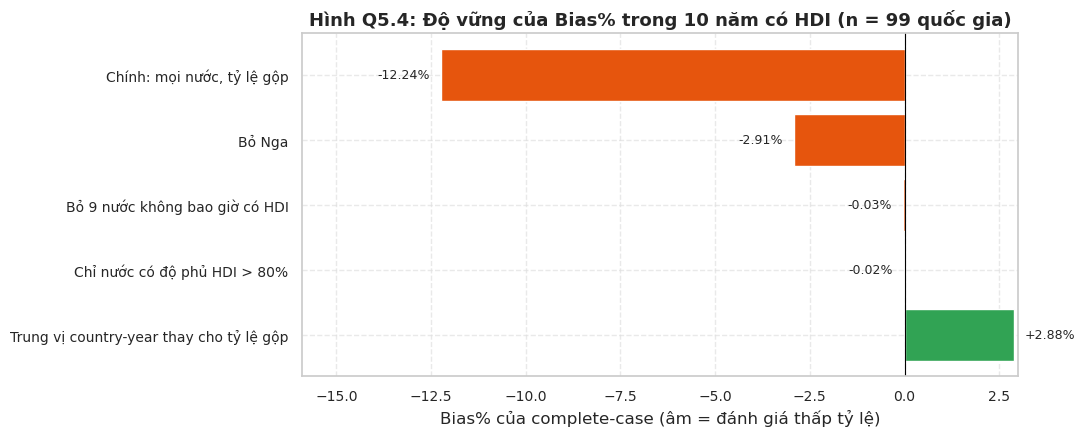

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.5))
q5_rb = q5_robust['bias_pct'][::-1]
ax.barh(q5_rb.index, q5_rb, color=np.where(q5_rb < 0, '#e6550d', '#31a354'))
for i, v in enumerate(q5_rb):
    ax.text(v - 0.3 if v < 0 else v + 0.3, i, f"{v:+.2f}%", va='center',
            ha='right' if v < 0 else 'left', fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(q5_rb.min() * 1.3, 3)
ax.set_xlabel('Bias% của complete-case (âm = đánh giá thấp tỷ lệ)')
ax.set_title('Hình Q5.4: Độ vững của Bias% trong 10 năm có HDI '
             f'(n = {q5_h["country"].nunique()} quốc gia)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig4_robustness.png')
plt.show()

### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q5)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng cụ thể):
> ✍️ **[TV3 tự viết trước khi khóa bài 27/11]** HDI thiếu theo cơ chế nào (MCAR hay không, bằng chứng nào); complete-case lệch bao nhiêu (tổng thể, theo nhóm tuổi và khu vực, kèm khoảng tin cậy 95%).

#### b) Giải thích cơ chế dữ liệu thiếu:
> ✍️ **[TV3 tự viết]** Hai nguồn thiếu (theo năm, theo quốc gia) chiếm bao nhiêu; vì sao complete-case bị lệch (nước nào bị loại và tỷ lệ nền của các nước đó).

#### c) Đánh giá tính vững của kết luận (Robustness Check - D6):
> ✍️ **[TV3 tự viết]** Kết luận còn đúng không khi bỏ Nga, bỏ 9 nước không bao giờ có HDI, chỉ giữ nước có độ phủ cao, dùng trung vị (Hình Q5.4).

#### d) Hàm ý thực tiễn, Điểm bất ngờ và Giới hạn:
> ✍️ **[TV3 tự viết]** Ý nghĩa cho người dùng mục tiêu; điểm bất ngờ; giới hạn (ví dụ: `income_group` là phân loại hiện tại; p-value coi các country-year là độc lập).

---
### 3.5. TỔNG KẾT VÀ PHẢN TƯ (SUMMARY AND REFLECTION)
- **3.5.1. Key findings:** 3–5 phát hiện cốt lõi quan trọng nhất, nêu bật điểm bất ngờ nhất.
- **3.5.2. Limitations:** Giới hạn của dữ liệu, phương pháp và phạm vi nghiên cứu.
- **3.5.3. Future work:** Hướng mở rộng nghiên cứu trong tương lai.
- **3.5.4. Individual reflection:** Từng thành viên tự viết phản tư cá nhân về khó khăn, cách vượt qua, bài học và việc dùng LLM.